### Standardization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/Social_Network_Ads.csv")
df = df.iloc[:,2:]
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


#### Train test split

In [10]:
X = df.iloc[:,:-1]
y = df.iloc[:,-1]

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test , y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=0)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((280, 2), (120, 2), (280,), (120,))

#### StandardScaler

In [15]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# fit the scaler to the train set, it will learn the parameters
scaler.fit(X_train)

# transform train and test
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
scaler.mean_

array([3.78642857e+01, 6.98071429e+04])

In [18]:
X_train_scaled[:5]

array([[-1.1631724 , -1.5849703 ],
       [ 2.17018137,  0.93098672],
       [ 0.0133054 ,  1.22017719],
       [ 0.20938504,  1.07558195],
       [ 0.40546467, -0.48604654]])

In [20]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns = X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns = X_test.columns)


In [21]:
np.round(X_train_scaled.describe(), 1)

,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.2,2.3


In [22]:
np.round(X_test_scaled.describe(), 1)

,Age,EstimatedSalary
count,120.0,120.0
mean,-0.1,-0.0
std,1.1,1.0
min,-1.9,-1.6
25%,-1.0,-0.7
50%,-0.2,-0.2
75%,0.7,0.5
max,2.2,2.3


#### Effect of scaling

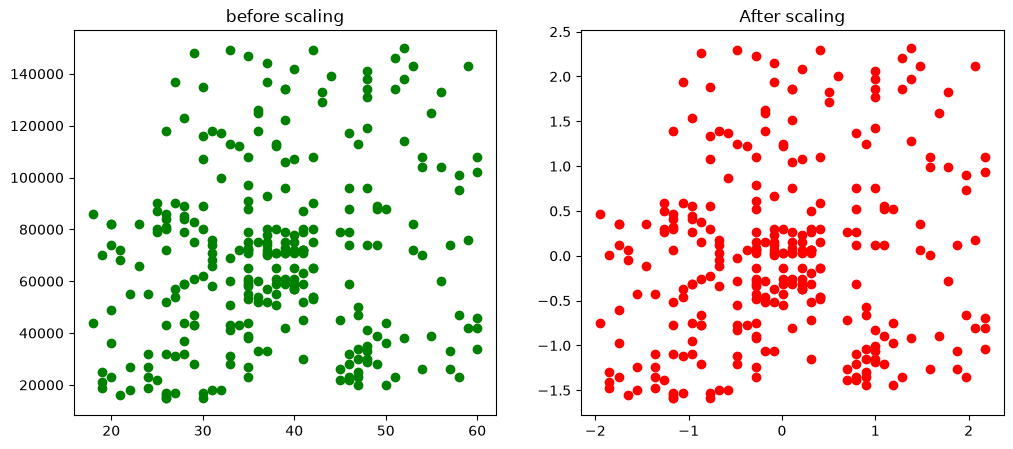

In [26]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))
ax1.scatter(X_train["Age"], X_train["EstimatedSalary"], c='green')
ax1.set_title("before scaling")
ax2.scatter(X_train_scaled["Age"], X_train_scaled["EstimatedSalary"], c='r')
ax2.set_title("After scaling")
plt.show()

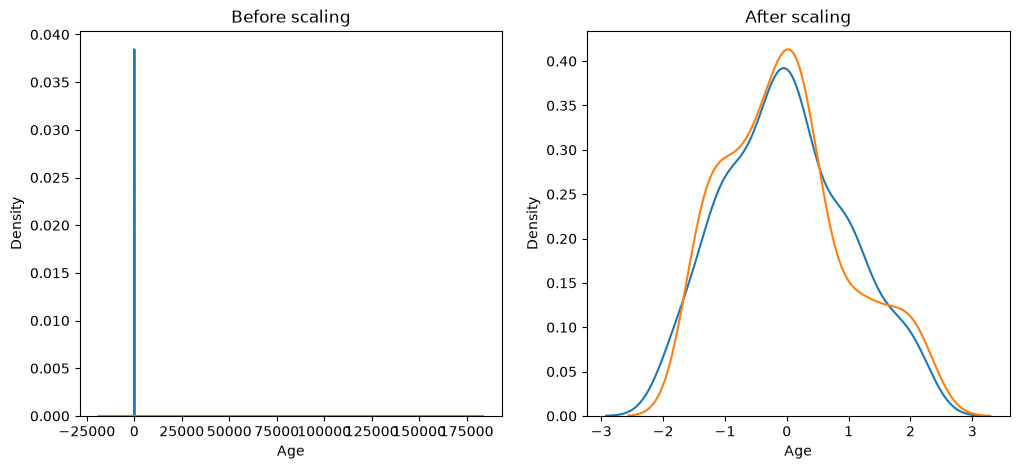

In [29]:
fig, (ax1, ax2) =plt.subplots(ncols=2, figsize=(12,5))

sns.kdeplot(X_train["Age"], ax=ax1)
sns.kdeplot(X_train["EstimatedSalary"], ax=ax1)
ax1.set_title("Before scaling")

sns.kdeplot(X_train_scaled["Age"], ax=ax2)
sns.kdeplot(X_train_scaled["EstimatedSalary"], ax=ax2)
ax2.set_title("After scaling")
plt.show()


#### Comparison of distribution

Text(0.5, 1.0, 'After scaling')

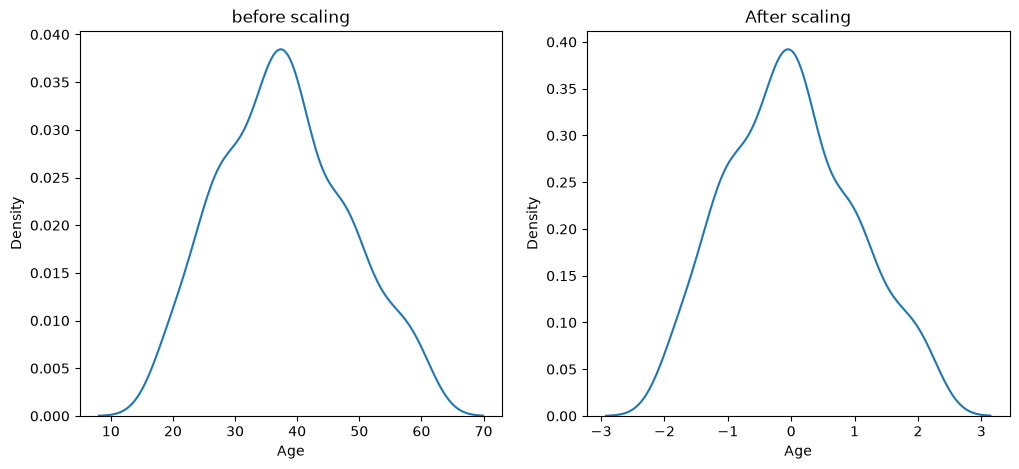

In [33]:
# Age
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))

sns.kdeplot(X_train["Age"], ax=ax1)
ax1.set_title('before scaling')
sns.kdeplot(X_train_scaled["Age"], ax=ax2)
ax2.set_title('After scaling')

Text(0.5, 1.0, 'After scaling')

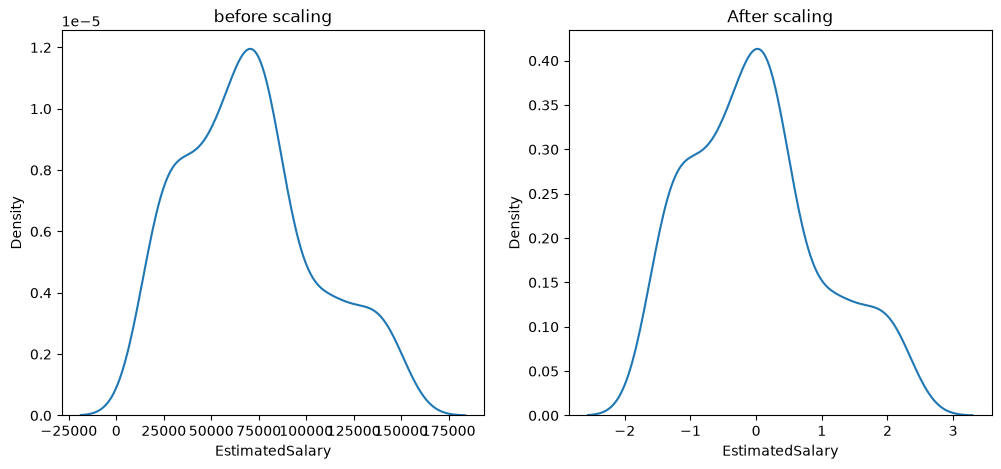

In [32]:
# Salary
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))

sns.kdeplot(X_train["EstimatedSalary"], ax=ax1)
ax1.set_title('before scaling')
sns.kdeplot(X_train_scaled["EstimatedSalary"], ax=ax2)
ax2.set_title('After scaling')

#### effect of outliers

In [34]:
new_df = pd.DataFrame({
    "Age" : [5, 90,95],
    'EstimatedSalary' : [1000, 250000, 350000],
    "Purchased": [0,1,1]
})
new_df

,Age,EstimatedSalary,Purchased
0,5,1000,0
1,90,250000,1
2,95,350000,1


In [53]:
df = pd.concat([df, new_df], axis=0)
df

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
1,90,250000,1
2,95,350000,1
0,5,1000,0
1,90,250000,1


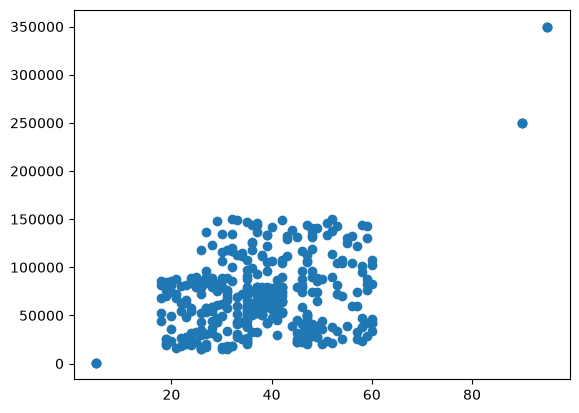

In [39]:
plt.scatter(df["Age"], df["EstimatedSalary"])
plt.show()

In [54]:
X = df.iloc[:,:-1]
y = df.iloc[:,-1]

from sklearn.model_selection import train_test_split
X_train, X_test , y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=0)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((288, 2), (124, 2), (288,), (124,))

In [55]:
X_train_scaled = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [56]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)

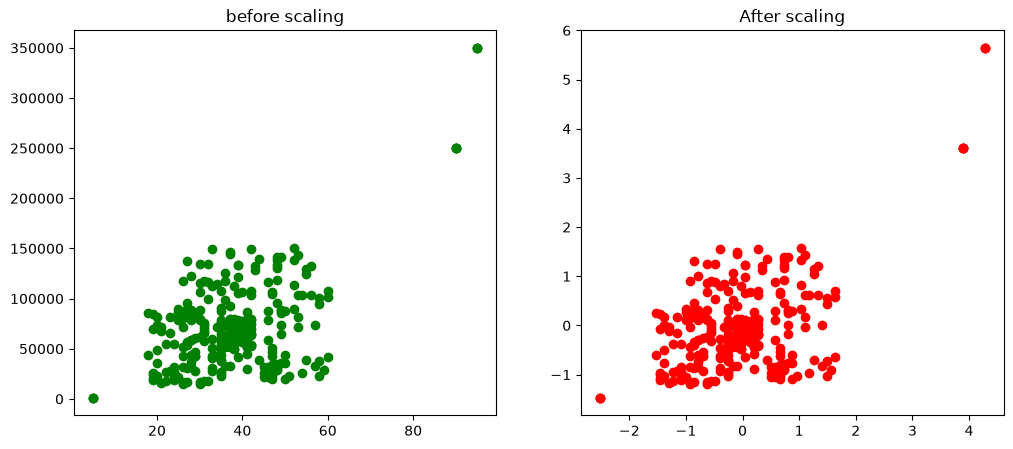

In [57]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))
ax1.scatter(X_train["Age"], X_train["EstimatedSalary"], c='green')
ax1.set_title("before scaling")
ax2.scatter(X_train_scaled["Age"], X_train_scaled["EstimatedSalary"], c='r')
ax2.set_title("After scaling")
plt.show()